<a href="https://colab.research.google.com/github/zainabkashif1/IoT-Intrusion-Detection-ML/blob/main/notebooks/03_Eight_Class_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import libraries
import pandas as pd
import numpy as np
import os

# Load the cleaned dataset
DATA_PATH = "/content/drive/MyDrive/shared iot/processed_data/cleaned_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Inspect all original attack labels
print("\nUnique Attack_Type labels:")
attack_labels = sorted(df["Attack_Type"].dropna().unique())

for label in attack_labels:
    print(label)

print("\nTotal unique attack labels:", len(attack_labels))


Mounted at /content/drive
Dataset shape: (730242, 41)

Columns:
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Attack_Type', 'Binary_Label']

Unique Attack_Type labels:
Backdoor_Malware
Benign_Final
BrowserHijacking
CommandInjection
DDoS-ACK_Fragmentation
DDoS-HTTP_Flood
DDoS-ICMP_Flood
DDoS-ICMP_Fragmentation
DDoS-PSHACK_FLOOD
DDoS-RSTFINFLOOD
DDoS-SYN_Flood
DDoS-SlowLoris
DDoS-SynonymousIP_Flood
DDoS-TCP_Flood
DDoS-UDP_Flood
DDoS-UDP_Fragmentation
DNS_Spoofing
DictionaryBruteForce
DoS-HTTP_Flood
DoS-SYN_Flood
DoS-TCP_Flood
DoS-UDP_Flood
MITM-ArpSpoofing
Mirai-greeth_flood
Mirai-greip_flood
Mirai-ud

In [ ]:
# Explicit mapping of all 34 original labels into 8 categories

attack_mapping = {
    "Benign_Final": "Benign",

    # DDoS
    "DDoS-ACK_Fragmentation": "DDoS",
    "DDoS-HTTP_Flood": "DDoS",
    "DDoS-ICMP_Flood": "DDoS",
    "DDoS-ICMP_Fragmentation": "DDoS",
    "DDoS-PSHACK_FLOOD": "DDoS",
    "DDoS-RSTFINFLOOD": "DDoS",
    "DDoS-SYN_Flood": "DDoS",
    "DDoS-SlowLoris": "DDoS",
    "DDoS-SynonymousIP_Flood": "DDoS",
    "DDoS-TCP_Flood": "DDoS",
    "DDoS-UDP_Flood": "DDoS",
    "DDoS-UDP_Fragmentation": "DDoS",

    # DoS
    "DoS-HTTP_Flood": "DoS",
    "DoS-SYN_Flood": "DoS",
    "DoS-TCP_Flood": "DoS",
    "DoS-UDP_Flood": "DoS",

    # Reconnaissance
    "Recon-HostDiscovery": "Recon",
    "Recon-OSScan": "Recon",
    "Recon-PingSweep": "Recon",
    "Recon-PortScan": "Recon",
    "VulnerabilityScan": "Recon",

    # Web-based
    "Backdoor_Malware": "Web-based",
    "BrowserHijacking": "Web-based",
    "CommandInjection": "Web-based",
    "SqlInjection": "Web-based",
    "Uploading_Attack": "Web-based",
    "XSS": "Web-based",

    # Brute Force
    "DictionaryBruteForce": "Brute Force",

    # Spoofing
    "DNS_Spoofing": "Spoofing",
    "MITM-ArpSpoofing": "Spoofing",

    # Mirai
    "Mirai-greeth_flood": "Mirai",
    "Mirai-greip_flood": "Mirai",
    "Mirai-udpplain": "Mirai"
}

# Apply mapping
df["Attack_Category"] = df["Attack_Type"].map(attack_mapping)

# Check for unmapped labels
unmapped = df[df["Attack_Category"].isna()]["Attack_Type"].value_counts()

if len(unmapped) > 0:
    print("ERROR: Unmapped labels found:")
    print(unmapped)
else:
    print("All original labels successfully mapped!")

# Display the 8-class distribution
print("\nClass distribution:")
print(df["Attack_Category"].value_counts())

print("\nNumber of classes:", df["Attack_Category"].nunique())

All original labels successfully mapped!

Class distribution:
Attack_Category
DDoS           489701
DoS            135318
Mirai           56142
Benign          23455
Recon           14752
Spoofing        10065
Web-based         530
Brute Force       279
Name: count, dtype: int64

Number of classes: 8


In [ ]:
# Separate input features and 8-class target

feature_columns = [
    col for col in df.columns
    if col not in ["Attack_Type", "Binary_Label", "Attack_Category"]
]

X = df[feature_columns].copy()
y = df["Attack_Category"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

# Generate a hash for each feature row
feature_hash = pd.util.hash_pandas_object(
    X,
    index=False
)

# Combine feature hashes with their corresponding labels
hash_labels = pd.DataFrame({
    "Feature_Hash": feature_hash,
    "Attack_Category": y
})

# Count how many different 8-class labels each feature group has
labels_per_group = hash_labels.groupby(
    "Feature_Hash"
)["Attack_Category"].nunique()

# Identify groups with conflicting labels
conflicting_groups = labels_per_group[
    labels_per_group > 1
].index

print("\nNumber of conflicting feature groups:",
      len(conflicting_groups))

# Identify all rows belonging to conflicting groups
conflicting_mask = feature_hash.isin(conflicting_groups)

print("Number of conflicting rows:",
      conflicting_mask.sum())

# Remove conflicting groups
df_8class = df.loc[~conflicting_mask].copy()

print("\nDataset shape after removing conflicts:",
      df_8class.shape)

print("\nClass distribution after conflict removal:")
print(df_8class["Attack_Category"].value_counts())

Feature shape: (730242, 39)
Target shape: (730242,)

Number of conflicting feature groups: 25592
Number of conflicting rows: 55486

Dataset shape after removing conflicts: (674756, 42)

Class distribution after conflict removal:
Attack_Category
DDoS           459857
DoS            109764
Mirai           56142
Benign          23430
Recon           14735
Spoofing        10023
Web-based         526
Brute Force       279
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Prepare features and labels after conflict removal
X_8 = df_8class[feature_columns].copy()
y_8 = df_8class["Attack_Category"].copy()

# Generate feature hashes again for the filtered dataset
groups_8 = pd.util.hash_pandas_object(
    X_8,
    index=False
)

# Create group-aware stratified split
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X_8, y_8, groups=groups_8)
)

# Split the data
X_train_8 = X_8.iloc[train_idx].copy()
X_test_8 = X_8.iloc[test_idx].copy()

y_train_8 = y_8.iloc[train_idx].copy()
y_test_8 = y_8.iloc[test_idx].copy()

# Display shapes
print("Training features:", X_train_8.shape)
print("Testing features:", X_test_8.shape)

# Check class distribution
print("\nTraining class distribution:")
print(y_train_8.value_counts())

print("\nTesting class distribution:")
print(y_test_8.value_counts())

# Verify that no feature groups overlap
train_groups = set(groups_8.iloc[train_idx])
test_groups = set(groups_8.iloc[test_idx])

overlap = train_groups.intersection(test_groups)

print("\nOverlapping feature groups:", len(overlap))

Training features: (539807, 39)
Testing features: (134949, 39)

Training class distribution:
Attack_Category
DDoS           368132
DoS             87783
Mirai           44716
Benign          18715
Recon           11824
Spoofing         7989
Web-based         424
Brute Force       224
Name: count, dtype: int64

Testing class distribution:
Attack_Category
DDoS           91725
DoS            21981
Mirai          11426
Benign          4715
Recon           2911
Spoofing        2034
Web-based        102
Brute Force       55
Name: count, dtype: int64

Overlapping feature groups: 0


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_8 = StandardScaler()

X_train_8_scaled = scaler_8.fit_transform(X_train_8)
X_test_8_scaled = scaler_8.transform(X_test_8)

print("Training:", X_train_8_scaled.shape)
print("Testing:", X_test_8_scaled.shape)

Training: (539807, 39)
Testing: (134949, 39)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

feature_selector_8 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

feature_selector_8.fit(X_train_8_scaled, y_train_8)

importance_8 = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": feature_selector_8.feature_importances_
})

importance_8 = importance_8.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(importance_8)

top_15_features_8 = importance_8.head(15)["Feature"].tolist()

print("\nTop 15 features:")
print(top_15_features_8)

,Feature,Importance
0,Rate,0.148420
1,IAT,0.146907
2,Tot size,0.084471
3,AVG,0.073560
4,Tot sum,0.062029
5,Max,0.055934
6,Protocol Type,0.043292
7,Number,0.035412
8,Header_Length,0.033608
9,Min,0.033325



Top 15 features:
['Rate', 'IAT', 'Tot size', 'AVG', 'Tot sum', 'Max', 'Protocol Type', 'Number', 'Header_Length', 'Min', 'Variance', 'Std', 'Time_To_Live', 'ack_flag_number', 'ack_count']


In [ ]:
top_15_indices_8 = [
    feature_columns.index(feature)
    for feature in top_15_features_8
]

# 39 features
X_train_39_8 = X_train_8_scaled
X_test_39_8 = X_test_8_scaled

# 15 features
X_train_15_8 = X_train_8_scaled[:, top_15_indices_8]
X_test_15_8 = X_test_8_scaled[:, top_15_indices_8]

print("39-feature training:", X_train_39_8.shape)
print("39-feature testing:", X_test_39_8.shape)

print("15-feature training:", X_train_15_8.shape)
print("15-feature testing:", X_test_15_8.shape)

39-feature training: (539807, 39)
39-feature testing: (134949, 39)
15-feature training: (539807, 15)
15-feature testing: (134949, 15)


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder_8 = LabelEncoder()

y_train_8_encoded = label_encoder_8.fit_transform(y_train_8)
y_test_8_encoded = label_encoder_8.transform(y_test_8)

print("Class encoding:")

for i, class_name in enumerate(label_encoder_8.classes_):
    print(f"{class_name}: {i}")

print("\nEncoded training labels:", y_train_8_encoded.shape)
print("Encoded testing labels:", y_test_8_encoded.shape)

Class encoding:
Benign: 0
Brute Force: 1
DDoS: 2
DoS: 3
Mirai: 4
Recon: 5
Spoofing: 6
Web-based: 7

Encoded training labels: (539807,)
Encoded testing labels: (134949,)


In [ ]:
import joblib
import os

SAVE_PATH = "/content/drive/MyDrive/shared iot/8class_saved"
os.makedirs(SAVE_PATH, exist_ok=True)

joblib.dump({
    "X_train_39": X_train_39_8,
    "X_test_39": X_test_39_8,
    "X_train_15": X_train_15_8,
    "X_test_15": X_test_15_8,
    "y_train": y_train_8,
    "y_test": y_test_8,
    "y_train_encoded": y_train_8_encoded,
    "y_test_encoded": y_test_8_encoded,
    "top_15_features": top_15_features_8,
    "label_encoder": label_encoder_8
}, SAVE_PATH + "/eight_class_data.joblib")

print("8-class data successfully saved!")

8-class data successfully saved!


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Train the baseline using all 39 features
baseline_39 = DummyClassifier(strategy="most_frequent")
baseline_39.fit(X_train_39_8, y_train_8)

# Predict on test data
baseline_pred_39 = baseline_39.predict(X_test_39_8)

# Evaluate
baseline_accuracy = accuracy_score(y_test_8, baseline_pred_39)

baseline_macro_f1 = f1_score(
    y_test_8,
    baseline_pred_39,
    average="macro",
    zero_division=0
)

print("Majority Class Baseline")
print("-----------------------")
print("Accuracy:", baseline_accuracy)
print("Macro-F1:", baseline_macro_f1)

print("\nClassification Report:")
print(classification_report(
    y_test_8,
    baseline_pred_39,
    labels=label_encoder_8.classes_,
    zero_division=0
))

Majority Class Baseline
-----------------------
Accuracy: 0.6797012204610631
Macro-F1: 0.10116400645861458

Classification Report:
              precision    recall  f1-score   support

      Benign       0.00      0.00      0.00      4715
 Brute Force       0.00      0.00      0.00        55
        DDoS       0.68      1.00      0.81     91725
         DoS       0.00      0.00      0.00     21981
       Mirai       0.00      0.00      0.00     11426
       Recon       0.00      0.00      0.00      2911
    Spoofing       0.00      0.00      0.00      2034
   Web-based       0.00      0.00      0.00       102

    accuracy                           0.68    134949
   macro avg       0.08      0.12      0.10    134949
weighted avg       0.46      0.68      0.55    134949



In [ ]:
import os

RESULTS_FOLDER = "/content/drive/MyDrive/shared iot/results"
os.makedirs(RESULTS_FOLDER, exist_ok=True)

baseline_results_8 = pd.DataFrame([{
    "Model": "Majority Baseline",
    "Features": 39,
    "Balancing": "None",
    "Accuracy": baseline_accuracy,
    "Macro-F1": baseline_macro_f1
}])

baseline_results_8.to_csv(
    os.path.join(RESULTS_FOLDER, "eight_class_results.csv"),
    index=False
)

display(baseline_results_8)

,Model,Features,Balancing,Accuracy,Macro-F1
0,Majority Baseline,39,None,0.679701,0.101164


## logistic regression
using 15 and 39 features

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Logistic Regression using all 39 features
lr_39_8 = LogisticRegression(max_iter=1000, random_state=42)
lr_39_8.fit(X_train_39_8, y_train_8)

pred_lr_39_8 = lr_39_8.predict(X_test_39_8)

acc_lr_39_8 = accuracy_score(y_test_8, pred_lr_39_8)
f1_lr_39_8 = f1_score(y_test_8, pred_lr_39_8, average="macro", zero_division=0)


# Logistic Regression using top 15 features
lr_15_8 = LogisticRegression(max_iter=1000, random_state=42)
lr_15_8.fit(X_train_15_8, y_train_8)

pred_lr_15_8 = lr_15_8.predict(X_test_15_8)

acc_lr_15_8 = accuracy_score(y_test_8, pred_lr_15_8)
f1_lr_15_8 = f1_score(y_test_8, pred_lr_15_8, average="macro", zero_division=0)


# Display results
lr_results_8 = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Features": 39,
        "Balancing": "None",
        "Accuracy": acc_lr_39_8,
        "Macro-F1": f1_lr_39_8
    },
    {
        "Model": "Logistic Regression",
        "Features": 15,
        "Balancing": "None",
        "Accuracy": acc_lr_15_8,
        "Macro-F1": f1_lr_15_8
    }
])

display(lr_results_8)

,Model,Features,Balancing,Accuracy,Macro-F1
0,Logistic Regression,39,None,0.840762,0.556466
1,Logistic Regression,15,None,0.824823,0.467454


## decision trees
using 15 and 39 features


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

# Decision Tree: 39 features
dt_39_8 = DecisionTreeClassifier(random_state=42)
dt_39_8.fit(X_train_39_8, y_train_8)

pred_dt_39_8 = dt_39_8.predict(X_test_39_8)

acc_dt_39_8 = accuracy_score(y_test_8, pred_dt_39_8)
f1_dt_39_8 = f1_score(y_test_8, pred_dt_39_8, average="macro", zero_division=0)


# Decision Tree: 15 features
dt_15_8 = DecisionTreeClassifier(random_state=42)
dt_15_8.fit(X_train_15_8, y_train_8)

pred_dt_15_8 = dt_15_8.predict(X_test_15_8)

acc_dt_15_8 = accuracy_score(y_test_8, pred_dt_15_8)
f1_dt_15_8 = f1_score(y_test_8, pred_dt_15_8, average="macro", zero_division=0)


# Display results
dt_results_8 = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Features": 39,
        "Balancing": "None",
        "Accuracy": acc_dt_39_8,
        "Macro-F1": f1_dt_39_8
    },
    {
        "Model": "Decision Tree",
        "Features": 15,
        "Balancing": "None",
        "Accuracy": acc_dt_15_8,
        "Macro-F1": f1_dt_15_8
    }
])

display(dt_results_8)

,Model,Features,Balancing,Accuracy,Macro-F1
0,Decision Tree,39,None,0.831129,0.620353
1,Decision Tree,15,None,0.813626,0.578932


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Random Forest: 39 features
rf_39_8 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_39_8.fit(X_train_39_8, y_train_8)
pred_rf_39_8 = rf_39_8.predict(X_test_39_8)

acc_rf_39_8 = accuracy_score(y_test_8, pred_rf_39_8)
f1_rf_39_8 = f1_score(
    y_test_8, pred_rf_39_8,
    average="macro", zero_division=0
)


# Random Forest: 15 features
rf_15_8 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_15_8.fit(X_train_15_8, y_train_8)
pred_rf_15_8 = rf_15_8.predict(X_test_15_8)

acc_rf_15_8 = accuracy_score(y_test_8, pred_rf_15_8)
f1_rf_15_8 = f1_score(
    y_test_8, pred_rf_15_8,
    average="macro", zero_division=0
)


# Display results
rf_results_8 = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Features": 39,
        "Balancing": "None",
        "Accuracy": acc_rf_39_8,
        "Macro-F1": f1_rf_39_8
    },
    {
        "Model": "Random Forest",
        "Features": 15,
        "Balancing": "None",
        "Accuracy": acc_rf_15_8,
        "Macro-F1": f1_rf_15_8
    }
])

display(rf_results_8)

,Model,Features,Balancing,Accuracy,Macro-F1
0,Random Forest,39,None,0.854478,0.648228
1,Random Forest,15,None,0.835012,0.616246


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

# XGBoost: 39 features
xgb_39_8 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_39_8.fit(X_train_39_8, y_train_8_encoded)

pred_xgb_39_8 = xgb_39_8.predict(X_test_39_8)

acc_xgb_39_8 = accuracy_score(y_test_8_encoded, pred_xgb_39_8)
f1_xgb_39_8 = f1_score(
    y_test_8_encoded, pred_xgb_39_8,
    average="macro", zero_division=0
)


# XGBoost: 15 features
xgb_15_8 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_15_8.fit(X_train_15_8, y_train_8_encoded)

pred_xgb_15_8 = xgb_15_8.predict(X_test_15_8)

acc_xgb_15_8 = accuracy_score(y_test_8_encoded, pred_xgb_15_8)
f1_xgb_15_8 = f1_score(
    y_test_8_encoded, pred_xgb_15_8,
    average="macro", zero_division=0
)


# Display results
xgb_results_8 = pd.DataFrame([
    {
        "Model": "XGBoost",
        "Features": 39,
        "Balancing": "None",
        "Accuracy": acc_xgb_39_8,
        "Macro-F1": f1_xgb_39_8
    },
    {
        "Model": "XGBoost",
        "Features": 15,
        "Balancing": "None",
        "Accuracy": acc_xgb_15_8,
        "Macro-F1": f1_xgb_15_8
    }
])

display(xgb_results_8)

,Model,Features,Balancing,Accuracy,Macro-F1
0,XGBoost,39,None,0.869929,0.666103
1,XGBoost,15,None,0.858613,0.612296


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

# MLP: 39 features
mlp_39_8 = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    max_iter=30,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

mlp_39_8.fit(X_train_39_8, y_train_8_encoded)

pred_mlp_39_8 = mlp_39_8.predict(X_test_39_8)

acc_mlp_39_8 = accuracy_score(y_test_8_encoded, pred_mlp_39_8)
f1_mlp_39_8 = f1_score(
    y_test_8_encoded, pred_mlp_39_8,
    average="macro", zero_division=0
)


# MLP: 15 features
mlp_15_8 = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    max_iter=30,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

mlp_15_8.fit(X_train_15_8, y_train_8_encoded)

pred_mlp_15_8 = mlp_15_8.predict(X_test_15_8)

acc_mlp_15_8 = accuracy_score(y_test_8_encoded, pred_mlp_15_8)
f1_mlp_15_8 = f1_score(
    y_test_8_encoded, pred_mlp_15_8,
    average="macro", zero_division=0
)


# Display results
mlp_results_8 = pd.DataFrame([
    {
        "Model": "MLP",
        "Features": 39,
        "Balancing": "None",
        "Accuracy": acc_mlp_39_8,
        "Macro-F1": f1_mlp_39_8
    },
    {
        "Model": "MLP",
        "Features": 15,
        "Balancing": "None",
        "Accuracy": acc_mlp_15_8,
        "Macro-F1": f1_mlp_15_8
    }
])

display(mlp_results_8)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Features,Balancing,Accuracy,Macro-F1
0,MLP,39,None,0.866023,0.636156
1,MLP,15,None,0.854627,0.580288


In [ ]:
import pandas as pd
import os

results_8 = pd.DataFrame([
    ["Majority Baseline", 39, "None", 0.679701, 0.101164],
    ["Logistic Regression", 39, "None", 0.840762, 0.556466],
    ["Logistic Regression", 15, "None", 0.824823, 0.467454],
    ["Decision Tree", 39, "None", 0.831129, 0.620353],
    ["Decision Tree", 15, "None", 0.813626, 0.578932],
    ["Random Forest", 39, "None", 0.854478, 0.648228],
    ["Random Forest", 15, "None", 0.835012, 0.616246],
    ["XGBoost", 39, "None", 0.869929, 0.666103],
    ["XGBoost", 15, "None", 0.858613, 0.612296]
], columns=["Model", "Features", "Balancing", "Accuracy", "Macro-F1"])

RESULTS_PATH = "/content/drive/MyDrive/shared iot/results"
os.makedirs(RESULTS_PATH, exist_ok=True)

results_8.to_csv(
    RESULTS_PATH + "/eight_class_results.csv",
    index=False
)

display(results_8)

print("Results saved to Google Drive!")

,Model,Features,Balancing,Accuracy,Macro-F1
0,Majority Baseline,39,None,0.679701,0.101164
1,Logistic Regression,39,None,0.840762,0.556466
2,Logistic Regression,15,None,0.824823,0.467454
3,Decision Tree,39,None,0.831129,0.620353
4,Decision Tree,15,None,0.813626,0.578932
5,Random Forest,39,None,0.854478,0.648228
6,Random Forest,15,None,0.835012,0.616246
7,XGBoost,39,None,0.869929,0.666103
8,XGBoost,15,None,0.858613,0.612296


Results saved to Google Drive!


In [ ]:
import os
import joblib
import pandas as pd

# Save all model results
results_8 = pd.DataFrame([
    ["Majority Baseline", 39, "None", 0.679701, 0.101164],
    ["Logistic Regression", 39, "None", 0.840762, 0.556466],
    ["Logistic Regression", 15, "None", 0.824823, 0.467454],
    ["Decision Tree", 39, "None", 0.831129, 0.620353],
    ["Decision Tree", 15, "None", 0.813626, 0.578932],
    ["Random Forest", 39, "None", 0.854478, 0.648228],
    ["Random Forest", 15, "None", 0.835012, 0.616246],
    ["XGBoost", 39, "None", 0.869929, 0.666103],
    ["XGBoost", 15, "None", 0.858613, 0.612296],
    ["MLP", 39, "None", 0.866023, 0.636156],
    ["MLP", 15, "None", 0.854627, 0.580288]
], columns=["Model", "Features", "Balancing", "Accuracy", "Macro-F1"])

RESULTS_PATH = "/content/drive/MyDrive/shared iot/results"
SAVE_PATH = "/content/drive/MyDrive/shared iot/8class_saved"

os.makedirs(RESULTS_PATH, exist_ok=True)
os.makedirs(SAVE_PATH, exist_ok=True)

results_8.to_csv(
    RESULTS_PATH + "/eight_class_results.csv",
    index=False
)

# Save prepared data
joblib.dump({
    "X_train_39": X_train_39_8,
    "X_test_39": X_test_39_8,
    "X_train_15": X_train_15_8,
    "X_test_15": X_test_15_8,
    "y_train": y_train_8,
    "y_test": y_test_8,
    "y_train_encoded": y_train_8_encoded,
    "y_test_encoded": y_test_8_encoded,
    "top_15_features": top_15_features_8,
    "label_encoder": label_encoder_8
}, SAVE_PATH + "/eight_class_data.joblib")

print("Results and prepared data saved successfully!")

Results and prepared data saved successfully!


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_39_8 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_39_8.fit(X_train_39_8, y_train_8)

pred_rf_39_8 = rf_39_8.predict(X_test_39_8)

print("Random Forest predictions generated!")

Random Forest predictions generated!


In [ ]:
from xgboost import XGBClassifier

xgb_39_8 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_39_8.fit(X_train_39_8, y_train_8_encoded)

pred_xgb_39_8 = xgb_39_8.predict(X_test_39_8)

print("XGBoost predictions generated!")

XGBoost predictions generated!


In [ ]:
import joblib
import os

SAVE_PATH = "/content/drive/MyDrive/shared iot/8class_saved"
os.makedirs(SAVE_PATH, exist_ok=True)

joblib.dump(
    {
        "random_forest": rf_39_8,
        "xgboost": xgb_39_8
    },
    SAVE_PATH + "/trained_models.joblib"
)

print("Both models saved!")

Both models saved!


## per-class classification report
for best performing models

In [ ]:
from sklearn.metrics import classification_report

# Random Forest report
rf_report = classification_report(
    y_test_8,
    pred_rf_39_8,
    labels=label_encoder_8.classes_,
    output_dict=True,
    zero_division=0
)

# XGBoost report
xgb_report = classification_report(
    y_test_8_encoded,
    pred_xgb_39_8,
    labels=range(8),
    target_names=label_encoder_8.classes_,
    output_dict=True,
    zero_division=0
)

rf_report_df = pd.DataFrame(rf_report).transpose()
xgb_report_df = pd.DataFrame(xgb_report).transpose()

display(rf_report_df)
display(xgb_report_df)

rf_report_df.to_csv(RESULTS_PATH + "/rf_8class_per_class_report.csv")
xgb_report_df.to_csv(RESULTS_PATH + "/xgb_8class_per_class_report.csv")

print("Classification reports saved!")

,precision,recall,f1-score,support
Benign,0.812783,0.876564,0.843469,4715.000000
Brute Force,0.800000,0.072727,0.133333,55.000000
DDoS,0.892890,0.915639,0.904121,91725.000000
DoS,0.606769,0.543196,0.573225,21981.000000
Mirai,0.999122,0.996062,0.997590,11426.000000
Recon,0.744402,0.742357,0.743378,2911.000000
Spoofing,0.935573,0.835300,0.882597,2034.000000
Web-based,0.666667,0.058824,0.108108,102.000000
accuracy,0.854478,0.854478,0.854478,0.854478
macro avg,0.807276,0.630084,0.648228,134949.000000


,precision,recall,f1-score,support
Benign,0.805165,0.886108,0.843700,4715.000000
Brute Force,0.714286,0.181818,0.289855,55.000000
DDoS,0.873645,0.968253,0.918519,91725.000000
DoS,0.758966,0.416860,0.538145,21981.000000
Mirai,0.999211,0.996937,0.998072,11426.000000
Recon,0.763335,0.742357,0.752699,2911.000000
Spoofing,0.942568,0.823009,0.878740,2034.000000
Web-based,0.750000,0.058824,0.109091,102.000000
accuracy,0.869929,0.869929,0.869929,0.869929
macro avg,0.825897,0.634271,0.666103,134949.000000


Classification reports saved!


## random forest with class weighting
for 15 and 39 features

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Random Forest with class weighting: 39 features
rf_weighted_39_8 = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_weighted_39_8.fit(X_train_39_8, y_train_8)

pred_rf_weighted_39_8 = rf_weighted_39_8.predict(X_test_39_8)


# Random Forest with class weighting: 15 features
rf_weighted_15_8 = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_weighted_15_8.fit(X_train_15_8, y_train_8)

pred_rf_weighted_15_8 = rf_weighted_15_8.predict(X_test_15_8)


# Results
rf_weighted_results_8 = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Features": 39,
        "Balancing": "Class Weight",
        "Accuracy": accuracy_score(y_test_8, pred_rf_weighted_39_8),
        "Macro-F1": f1_score(y_test_8, pred_rf_weighted_39_8, average="macro", zero_division=0)
    },
    {
        "Model": "Random Forest",
        "Features": 15,
        "Balancing": "Class Weight",
        "Accuracy": accuracy_score(y_test_8, pred_rf_weighted_15_8),
        "Macro-F1": f1_score(y_test_8, pred_rf_weighted_15_8, average="macro", zero_division=0)
    }
])

display(rf_weighted_results_8)

,Model,Features,Balancing,Accuracy,Macro-F1
0,Random Forest,39,Class Weight,0.854834,0.668270
1,Random Forest,15,Class Weight,0.826268,0.609141


In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

# Per-class report for weighted Random Forest (39 features)
weighted_rf_report_39 = pd.DataFrame(
    classification_report(
        y_test_8,
        pred_rf_weighted_39_8,
        target_names=label_encoder_8.classes_,
        output_dict=True,
        zero_division=0
    )
).transpose()

display(weighted_rf_report_39)

# Save report
weighted_rf_report_39.to_csv(
    "/content/drive/MyDrive/shared iot/results/rf_weighted_8class_per_class_report.csv"
)

,precision,recall,f1-score,support
Benign,0.806576,0.884411,0.843703,4715.000000
Brute Force,0.588235,0.181818,0.277778,55.000000
DDoS,0.891321,0.918179,0.904551,91725.000000
DoS,0.610355,0.534689,0.570022,21981.000000
Mirai,0.999210,0.995712,0.997457,11426.000000
Recon,0.754597,0.733081,0.743684,2911.000000
Spoofing,0.940390,0.829892,0.881692,2034.000000
Web-based,0.875000,0.068627,0.127273,102.000000
accuracy,0.854834,0.854834,0.854834,0.854834
macro avg,0.808211,0.643301,0.668270,134949.000000


## weighted xgboost
with 15 and 39 features

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.class_weight import compute_sample_weight

# Calculate balanced sample weights
sample_weights_8 = compute_sample_weight(
    class_weight="balanced",
    y=y_train_8
)

# XGBoost with class weighting: 39 features
xgb_weighted_39_8 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_weighted_39_8.fit(
    X_train_39_8,
    y_train_8_encoded,
    sample_weight=sample_weights_8
)

pred_xgb_weighted_39_8 = xgb_weighted_39_8.predict(X_test_39_8)


# XGBoost with class weighting: 15 features
xgb_weighted_15_8 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_weighted_15_8.fit(
    X_train_15_8,
    y_train_8_encoded,
    sample_weight=sample_weights_8
)

pred_xgb_weighted_15_8 = xgb_weighted_15_8.predict(X_test_15_8)


# Results
xgb_weighted_results_8 = pd.DataFrame([
    {
        "Model": "XGBoost",
        "Features": 39,
        "Balancing": "Class Weight",
        "Accuracy": accuracy_score(y_test_8_encoded, pred_xgb_weighted_39_8),
        "Macro-F1": f1_score(y_test_8_encoded, pred_xgb_weighted_39_8, average="macro", zero_division=0)
    },
    {
        "Model": "XGBoost",
        "Features": 15,
        "Balancing": "Class Weight",
        "Accuracy": accuracy_score(y_test_8_encoded, pred_xgb_weighted_15_8),
        "Macro-F1": f1_score(y_test_8_encoded, pred_xgb_weighted_15_8, average="macro", zero_division=0)
    }
])

display(xgb_weighted_results_8)

,Model,Features,Balancing,Accuracy,Macro-F1
0,XGBoost,39,Class Weight,0.788609,0.636065
1,XGBoost,15,Class Weight,0.696345,0.585762


In [ ]:
xgb_weighted_results_8.to_csv(
    "/content/drive/MyDrive/shared iot/results/xgb_weighted_8class_results.csv",
    index=False
)

print("Weighted XGBoost results saved!")

Weighted XGBoost results saved!


In [ ]:
weighted_xgb_report_39 = pd.DataFrame(
    classification_report(
        y_test_8_encoded,
        pred_xgb_weighted_39_8,
        target_names=label_encoder_8.classes_,
        output_dict=True,
        zero_division=0
    )
).transpose()

display(weighted_xgb_report_39)

weighted_xgb_report_39.to_csv(
    "/content/drive/MyDrive/shared iot/results/xgb_weighted_8class_per_class_report.csv"
)

,precision,recall,f1-score,support
Benign,0.859506,0.782397,0.819141,4715.000000
Brute Force,0.075758,0.363636,0.125392,55.000000
DDoS,0.967895,0.739853,0.838648,91725.000000
DoS,0.453120,0.897684,0.602246,21981.000000
Mirai,0.993983,0.997549,0.995763,11426.000000
Recon,0.741419,0.667812,0.702693,2911.000000
Spoofing,0.925846,0.847099,0.884724,2034.000000
Web-based,0.067775,0.519608,0.119910,102.000000
accuracy,0.788609,0.788609,0.788609,0.788609
macro avg,0.635663,0.726955,0.636065,134949.000000


In [ ]:
rf_weighted_results_8.to_csv(
    "/content/drive/MyDrive/shared iot/results/rf_weighted_8class_results.csv",
    index=False
)

In [ ]:
import joblib
import pandas as pd
import numpy as np

saved_data = joblib.load(
    "/content/drive/MyDrive/shared iot/8class_saved/eight_class_data.joblib"
)

print("Saved object type:", type(saved_data))

if isinstance(saved_data, dict):
    print("\nAvailable saved variables:")
    for key, value in saved_data.items():
        print(key, type(value), getattr(value, "shape", ""))
else:
    print(saved_data)

Saved object type: <class 'dict'>

Available saved variables:
X_train_39 <class 'numpy.ndarray'> (539807, 39)
X_test_39 <class 'numpy.ndarray'> (134949, 39)
X_train_15 <class 'numpy.ndarray'> (539807, 15)
X_test_15 <class 'numpy.ndarray'> (134949, 15)
y_train <class 'pandas.core.series.Series'> (539807,)
y_test <class 'pandas.core.series.Series'> (134949,)
y_train_encoded <class 'numpy.ndarray'> (539807,)
y_test_encoded <class 'numpy.ndarray'> (134949,)
top_15_features <class 'list'> 
label_encoder <class 'sklearn.preprocessing._label.LabelEncoder'> 


In [ ]:
# Restore the saved variables using the names in our 8-class notebook

X_train_39_8 = saved_data["X_train_39"]
X_test_39_8 = saved_data["X_test_39"]

X_train_15_8 = saved_data["X_train_15"]
X_test_15_8 = saved_data["X_test_15"]

y_train_8 = saved_data["y_train"]
y_test_8 = saved_data["y_test"]

y_train_8_encoded = saved_data["y_train_encoded"]
y_test_8_encoded = saved_data["y_test_encoded"]

top_15_features_8 = saved_data["top_15_features"]
label_encoder_8 = saved_data["label_encoder"]

# Recreate the feature indices
feature_columns = list(saved_data["top_15_features"])

print("Training data restored successfully!")
print("39 features:", X_train_39_8.shape)
print("15 features:", X_train_15_8.shape)
print("Encoded training labels:", y_train_8_encoded.shape)
print("Encoded testing labels:", y_test_8_encoded.shape)

Training data restored successfully!
39 features: (539807, 39)
15 features: (539807, 15)
Encoded training labels: (539807,)
Encoded testing labels: (134949,)


In [ ]:
top_15_indices_8 = []

for i in range(X_train_15_8.shape[1]):
    for j in range(X_train_39_8.shape[1]):
        if np.array_equal(
            X_train_15_8[:, i],
            X_train_39_8[:, j]
        ):
            top_15_indices_8.append(j)
            break

print("Recovered feature indices:", top_15_indices_8)
print("Number of indices:", len(top_15_indices_8))

Recovered feature indices: [3, 36, 33, 33, 30, 32, 1, 37, 0, 31, 38, 34, 2, 8, 11]
Number of indices: 15


In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# ----------------------------------
# 1. Apply SMOTE to training data
# ----------------------------------

class_counts = pd.Series(y_train_8_encoded).value_counts()

print("Original training class counts:")
print(class_counts.sort_index())

# Encodings:
# 1 = Brute Force
# 7 = Web-based

smote = SMOTE(
    sampling_strategy={
        1: 5000,
        7: 5000
    },
    random_state=42,
    k_neighbors=5
)

X_train_smote_39_8, y_train_smote_8 = smote.fit_resample(
    X_train_39_8.astype("float32"),
    y_train_8_encoded
)

print("\nResampled training class counts:")
print(pd.Series(y_train_smote_8).value_counts().sort_index())


# ----------------------------------
# 2. Create the 15-feature dataset
# ----------------------------------

X_train_smote_15_8 = X_train_smote_39_8[:, top_15_indices_8]


# ----------------------------------
# 3. Random Forest: 39 features
# ----------------------------------

rf_smote_39_8 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote_39_8.fit(
    X_train_smote_39_8,
    y_train_smote_8
)

pred_rf_smote_39_8 = rf_smote_39_8.predict(X_test_39_8)


# ----------------------------------
# 4. Random Forest: 15 features
# ----------------------------------

rf_smote_15_8 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote_15_8.fit(
    X_train_smote_15_8,
    y_train_smote_8
)

pred_rf_smote_15_8 = rf_smote_15_8.predict(X_test_15_8)


# ----------------------------------
# 5. Evaluate both models
# ----------------------------------

rf_smote_results_8 = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Features": 39,
        "Balancing": "SMOTE",
        "Accuracy": accuracy_score(
            y_test_8_encoded,
            pred_rf_smote_39_8
        ),
        "Macro-F1": f1_score(
            y_test_8_encoded,
            pred_rf_smote_39_8,
            average="macro",
            zero_division=0
        )
    },
    {
        "Model": "Random Forest",
        "Features": 15,
        "Balancing": "SMOTE",
        "Accuracy": accuracy_score(
            y_test_8_encoded,
            pred_rf_smote_15_8
        ),
        "Macro-F1": f1_score(
            y_test_8_encoded,
            pred_rf_smote_15_8,
            average="macro",
            zero_division=0
        )
    }
])

display(rf_smote_results_8)

Original training class counts:
0     18715
1       224
2    368132
3     87783
4     44716
5     11824
6      7989
7       424
Name: count, dtype: int64

Resampled training class counts:
0     18715
1      5000
2    368132
3     87783
4     44716
5     11824
6      7989
7      5000
Name: count, dtype: int64


,Model,Features,Balancing,Accuracy,Macro-F1
0,Random Forest,39,SMOTE,0.854256,0.668157
1,Random Forest,15,SMOTE,0.834048,0.614856


In [ ]:
import joblib

saved_models = joblib.load(
    "/content/drive/MyDrive/shared iot/8class_saved/trained_models.joblib"
)

print("Saved object type:", type(saved_models))

if isinstance(saved_models, dict):
    print("\nAvailable saved variables:")
    for key, value in saved_models.items():
        print(key, type(value), getattr(value, "shape", ""))
else:
    print(saved_models)

Saved object type: <class 'dict'>

Available saved variables:
random_forest <class 'sklearn.ensemble._forest.RandomForestClassifier'> 
xgboost <class 'xgboost.sklearn.XGBClassifier'> 


In [ ]:
rf_smote_results_8.to_csv(
    "/content/drive/MyDrive/shared iot/results/rf_smote_8class_results.csv",
    index=False
)

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

rf_smote_report_39 = pd.DataFrame(
    classification_report(
        y_test_8_encoded,
        pred_rf_smote_39_8,
        target_names=label_encoder_8.classes_,
        output_dict=True,
        zero_division=0
    )
).transpose()

rf_smote_report_15 = pd.DataFrame(
    classification_report(
        y_test_8_encoded,
        pred_rf_smote_15_8,
        target_names=label_encoder_8.classes_,
        output_dict=True,
        zero_division=0
    )
).transpose()

display(rf_smote_report_39)
display(rf_smote_report_15)

rf_smote_report_39.to_csv(
    "/content/drive/MyDrive/shared iot/results/rf_smote_8class_39_per_class_report.csv"
)

rf_smote_report_15.to_csv(
    "/content/drive/MyDrive/shared iot/results/rf_smote_8class_15_per_class_report.csv"
)

,precision,recall,f1-score,support
Benign,0.814500,0.874443,0.843408,4715.000000
Brute Force,0.400000,0.181818,0.250000,55.000000
DDoS,0.892780,0.915410,0.903954,91725.000000
DoS,0.605942,0.542787,0.572628,21981.000000
Mirai,0.999122,0.996062,0.997590,11426.000000
Recon,0.748707,0.746135,0.747419,2911.000000
Spoofing,0.938821,0.829892,0.881002,2034.000000
Web-based,0.312500,0.098039,0.149254,102.000000
accuracy,0.854256,0.854256,0.854256,0.854256
macro avg,0.714047,0.648073,0.668157,134949.000000


,precision,recall,f1-score,support
Benign,0.715361,0.786214,0.749116,4715.000000
Brute Force,0.090909,0.036364,0.051948,55.000000
DDoS,0.867175,0.881025,0.874045,91725.000000
DoS,0.471544,0.443656,0.457175,21981.000000
Mirai,0.846249,0.834325,0.840245,11426.000000
Recon,0.642542,0.649605,0.646054,2911.000000
Spoofing,0.653752,0.522616,0.580874,2034.000000
Web-based,0.100000,0.039216,0.056338,102.000000
accuracy,0.791143,0.791143,0.791143,0.791143
macro avg,0.548441,0.524127,0.531974,134949.000000


In [ ]:
rf_smote_report_39.to_csv(
    "/content/drive/MyDrive/shared iot/results/rf_smote_8class_39_per_class_report.csv"
)

rf_smote_report_15.to_csv(
    "/content/drive/MyDrive/shared iot/results/rf_smote_8class_15_per_class_report.csv"
)

## xgboobst with smote

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

# ----------------------------------
# XGBoost: 39 features with SMOTE
# ----------------------------------

xgb_smote_39_8 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_smote_39_8.fit(
    X_train_smote_39_8,
    y_train_smote_8
)

pred_xgb_smote_39_8 = xgb_smote_39_8.predict(X_test_39_8)


# ----------------------------------
# XGBoost: 15 features with SMOTE
# ----------------------------------

xgb_smote_15_8 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_smote_15_8.fit(
    X_train_smote_15_8,
    y_train_smote_8
)

pred_xgb_smote_15_8 = xgb_smote_15_8.predict(X_test_15_8)


# ----------------------------------
# Results
# ----------------------------------

xgb_smote_results_8 = pd.DataFrame([
    {
        "Model": "XGBoost",
        "Features": 39,
        "Balancing": "SMOTE",
        "Accuracy": accuracy_score(y_test_8_encoded, pred_xgb_smote_39_8),
        "Macro-F1": f1_score(y_test_8_encoded, pred_xgb_smote_39_8, average="macro", zero_division=0)
    },
    {
        "Model": "XGBoost",
        "Features": 15,
        "Balancing": "SMOTE",
        "Accuracy": accuracy_score(y_test_8_encoded, pred_xgb_smote_15_8),
        "Macro-F1": f1_score(y_test_8_encoded, pred_xgb_smote_15_8, average="macro", zero_division=0)
    }
])

display(xgb_smote_results_8)

,Model,Features,Balancing,Accuracy,Macro-F1
0,XGBoost,39,SMOTE,0.869558,0.679592
1,XGBoost,15,SMOTE,0.857872,0.616624


In [ ]:
xgb_smote_results_8.to_csv(
    "/content/drive/MyDrive/shared iot/results/xgb_smote_8class_results.csv",
    index=False
)

print("XGBoost SMOTE results saved!")

XGBoost SMOTE results saved!


In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

# 39-feature report
xgb_smote_report_39 = pd.DataFrame(
    classification_report(
        y_test_8_encoded,
        pred_xgb_smote_39_8,
        target_names=label_encoder_8.classes_,
        output_dict=True,
        zero_division=0
    )
).transpose()

# 15-feature report
xgb_smote_report_15 = pd.DataFrame(
    classification_report(
        y_test_8_encoded,
        pred_xgb_smote_15_8,
        target_names=label_encoder_8.classes_,
        output_dict=True,
        zero_division=0
    )
).transpose()

display(xgb_smote_report_39)
display(xgb_smote_report_15)

,precision,recall,f1-score,support
Benign,0.814437,0.880594,0.846224,4715.000000
Brute Force,0.375000,0.218182,0.275862,55.000000
DDoS,0.873486,0.967991,0.918314,91725.000000
DoS,0.757182,0.416087,0.537052,21981.000000
Mirai,0.998860,0.996849,0.997854,11426.000000
Recon,0.758366,0.739608,0.748870,2911.000000
Spoofing,0.948198,0.827925,0.883990,2034.000000
Web-based,0.273973,0.196078,0.228571,102.000000
accuracy,0.869558,0.869558,0.869558,0.869558
macro avg,0.724938,0.655414,0.679592,134949.000000


,precision,recall,f1-score,support
Benign,0.783158,0.854083,0.817084,4715.000000
Brute Force,0.063492,0.072727,0.067797,55.000000
DDoS,0.855586,0.979831,0.913503,91725.000000
DoS,0.787861,0.311223,0.446191,21981.000000
Mirai,0.998421,0.996324,0.997372,11426.000000
Recon,0.719409,0.668499,0.693020,2911.000000
Spoofing,0.934335,0.825467,0.876534,2034.000000
Web-based,0.116071,0.127451,0.121495,102.000000
accuracy,0.857872,0.857872,0.857872,0.857872
macro avg,0.657292,0.604451,0.616624,134949.000000


In [ ]:
xgb_smote_report_39.to_csv(
    "/content/drive/MyDrive/shared iot/results/xgb_smote_8class_39_per_class_report.csv"
)

xgb_smote_report_15.to_csv(
    "/content/drive/MyDrive/shared iot/results/xgb_smote_8class_15_per_class_report.csv"
)

print("Both XGBoost per-class reports saved!")

Both XGBoost per-class reports saved!


In [ ]:
import pandas as pd
import os

RESULTS_PATH = "/content/drive/MyDrive/shared iot/results"
FIGURES_PATH = os.path.join(RESULTS_PATH, "figures")

os.makedirs(FIGURES_PATH, exist_ok=True)

# Load all five result files
original_results = pd.read_csv(
    os.path.join(RESULTS_PATH, "eight_class_results.csv")
)

rf_weighted = pd.read_csv(
    os.path.join(RESULTS_PATH, "rf_weighted_8class_results.csv")
)

xgb_weighted = pd.read_csv(
    os.path.join(RESULTS_PATH, "xgb_weighted_8class_results.csv")
)

rf_smote = pd.read_csv(
    os.path.join(RESULTS_PATH, "rf_smote_8class_results.csv")
)

xgb_smote = pd.read_csv(
    os.path.join(RESULTS_PATH, "xgb_smote_8class_results.csv")
)

# Combine everything
eight_class_master_results = pd.concat(
    [
        original_results,
        rf_weighted,
        xgb_weighted,
        rf_smote,
        xgb_smote
    ],
    ignore_index=True
)

# Remove any accidental index columns
eight_class_master_results = eight_class_master_results.loc[
    :, ~eight_class_master_results.columns.str.contains("^Unnamed")
]

# Save master CSV
eight_class_master_results.to_csv(
    os.path.join(RESULTS_PATH, "eight_class_master_results.csv"),
    index=False
)

print("Total experiments:", len(eight_class_master_results))
display(eight_class_master_results)

Total experiments: 19


,Model,Features,Balancing,Accuracy,Macro-F1
0,Majority Baseline,39,NaN,0.679701,0.101164
1,Logistic Regression,39,NaN,0.840762,0.556466
2,Logistic Regression,15,NaN,0.824823,0.467454
3,Decision Tree,39,NaN,0.831129,0.620353
4,Decision Tree,15,NaN,0.813626,0.578932
5,Random Forest,39,NaN,0.854478,0.648228
6,Random Forest,15,NaN,0.835012,0.616246
7,XGBoost,39,NaN,0.869929,0.666103
8,XGBoost,15,NaN,0.858613,0.612296
9,MLP,39,NaN,0.866023,0.636156


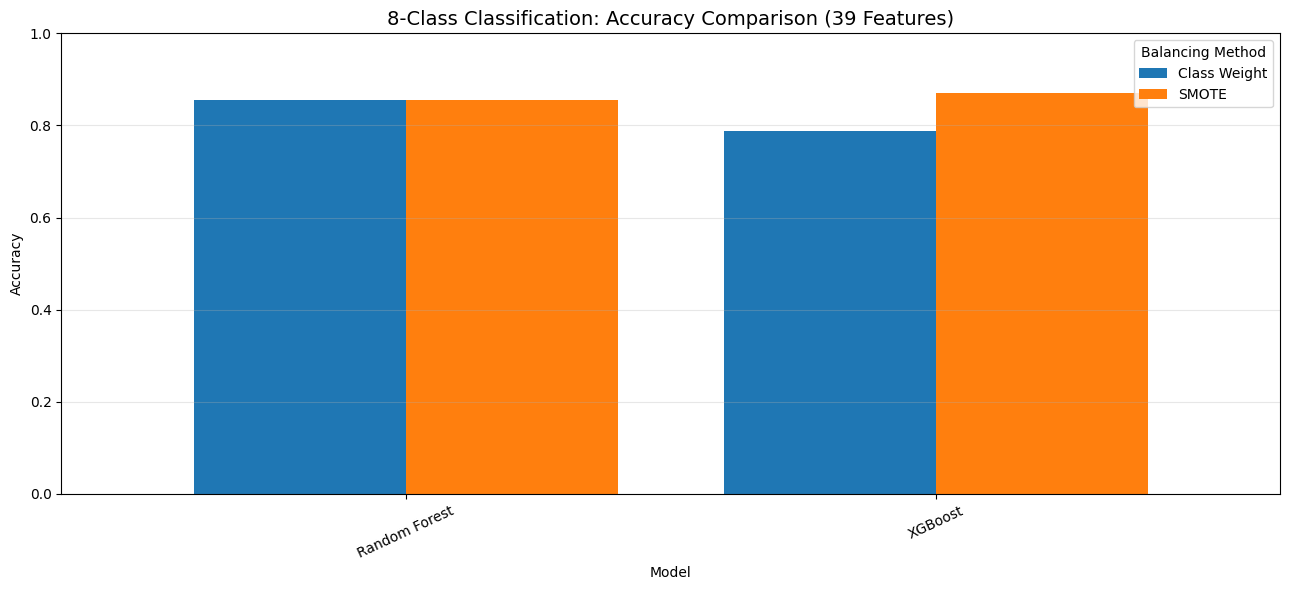

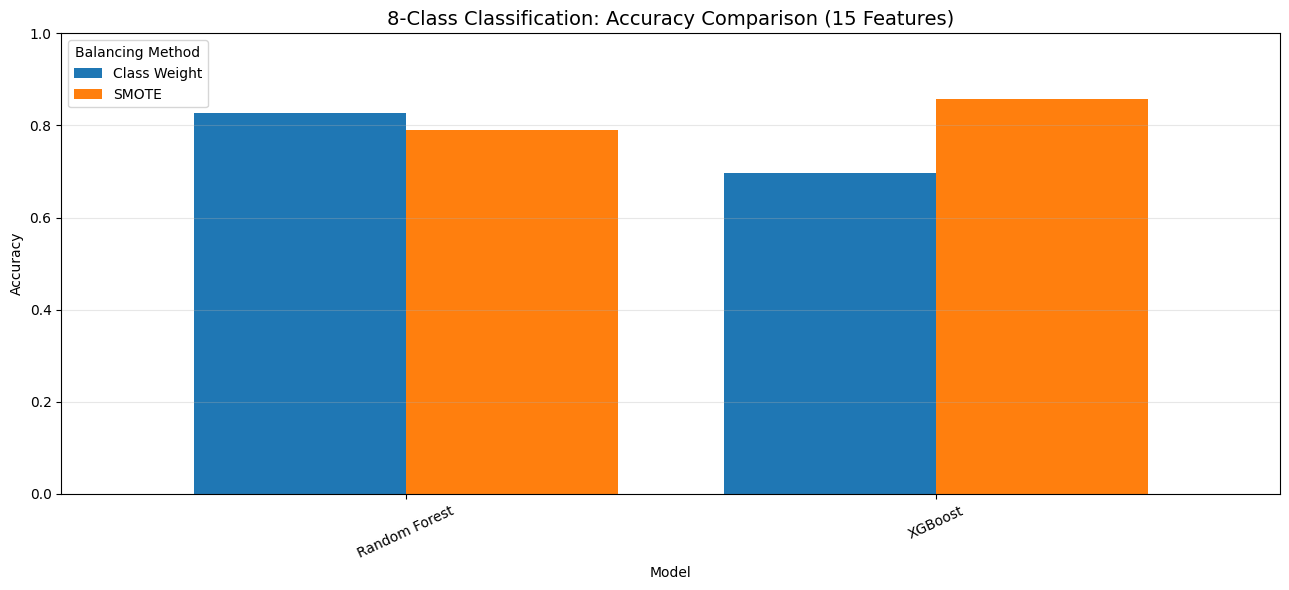

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_metric_comparison(data, metric, feature_count, filename):

    plot_data = data[data["Features"] == feature_count]

    pivot_data = plot_data.pivot_table(
        index="Model",
        columns="Balancing",
        values=metric,
        aggfunc="first"
    )

    model_order = [
        "Majority Baseline",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "MLP"
    ]

    model_order = [
        model for model in model_order
        if model in pivot_data.index
    ]

    pivot_data = pivot_data.reindex(model_order)

    ax = pivot_data.plot(
        kind="bar",
        figsize=(13, 6),
        width=0.8
    )

    ax.set_title(
        f"8-Class Classification: {metric} Comparison ({feature_count} Features)",
        fontsize=14
    )

    ax.set_xlabel("Model")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.legend(title="Balancing Method")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        os.path.join(FIGURES_PATH, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# Accuracy graphs
plot_metric_comparison(
    eight_class_master_results,
    "Accuracy",
    39,
    "accuracy_comparison_8class_39.png"
)

plot_metric_comparison(
    eight_class_master_results,
    "Accuracy",
    15,
    "accuracy_comparison_8class_15.png"
)

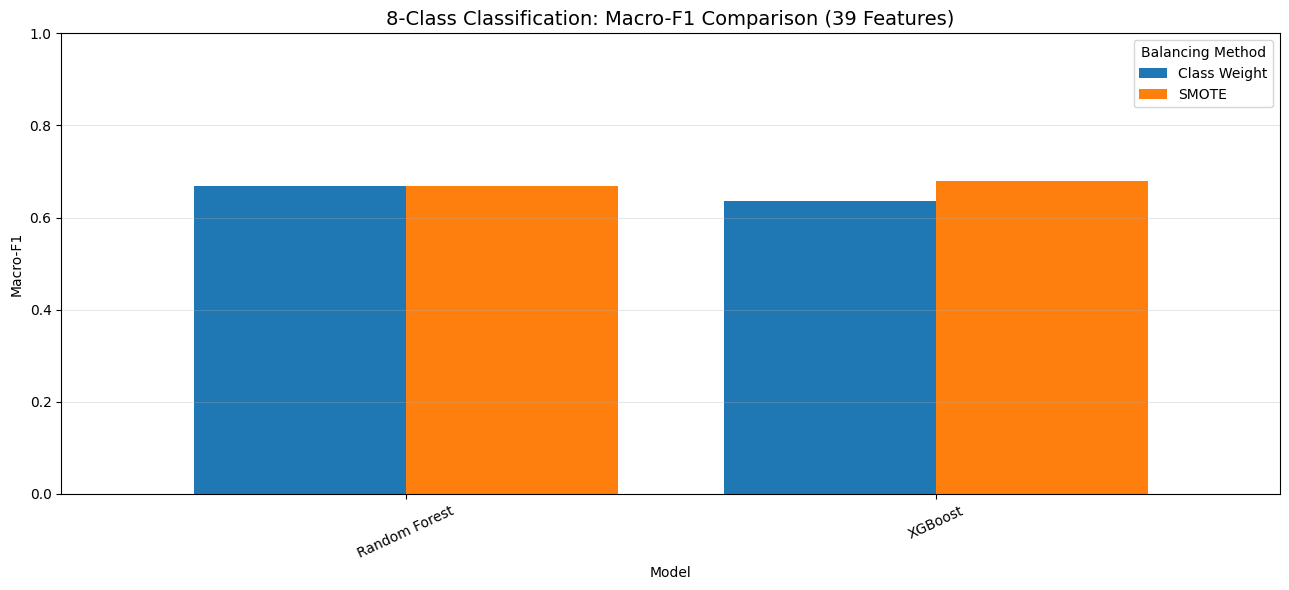

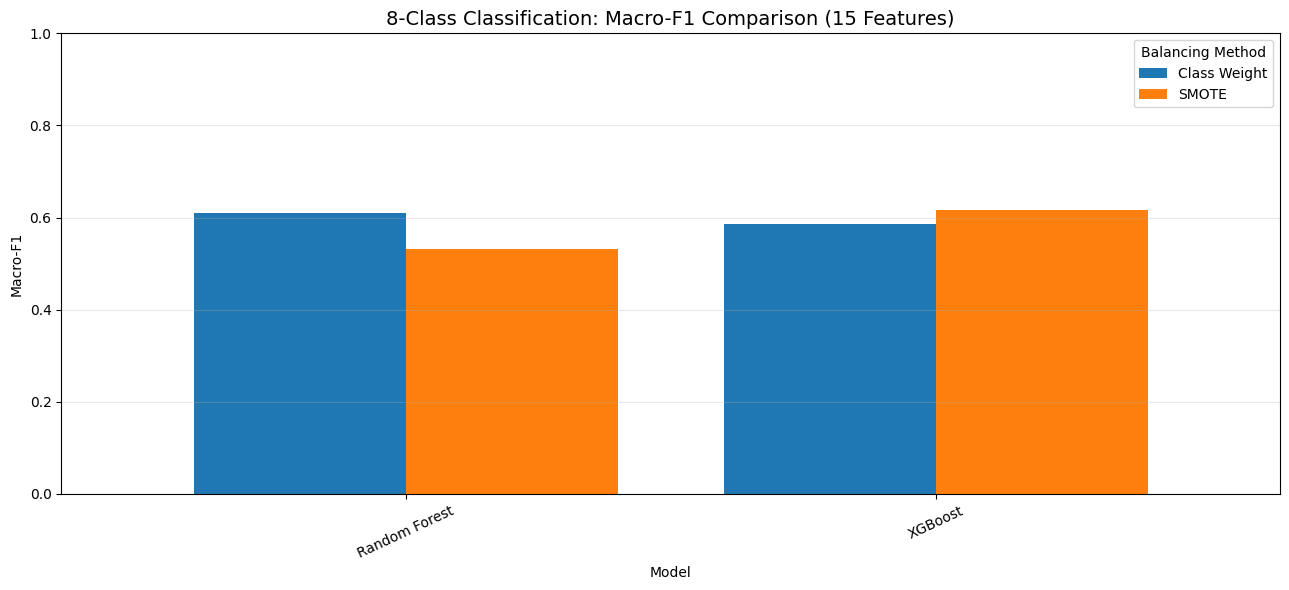

In [ ]:
# Macro-F1 graphs
plot_metric_comparison(
    eight_class_master_results,
    "Macro-F1",
    39,
    "macro_f1_comparison_8class_39.png"
)

plot_metric_comparison(
    eight_class_master_results,
    "Macro-F1",
    15,
    "macro_f1_comparison_8class_15.png"
)

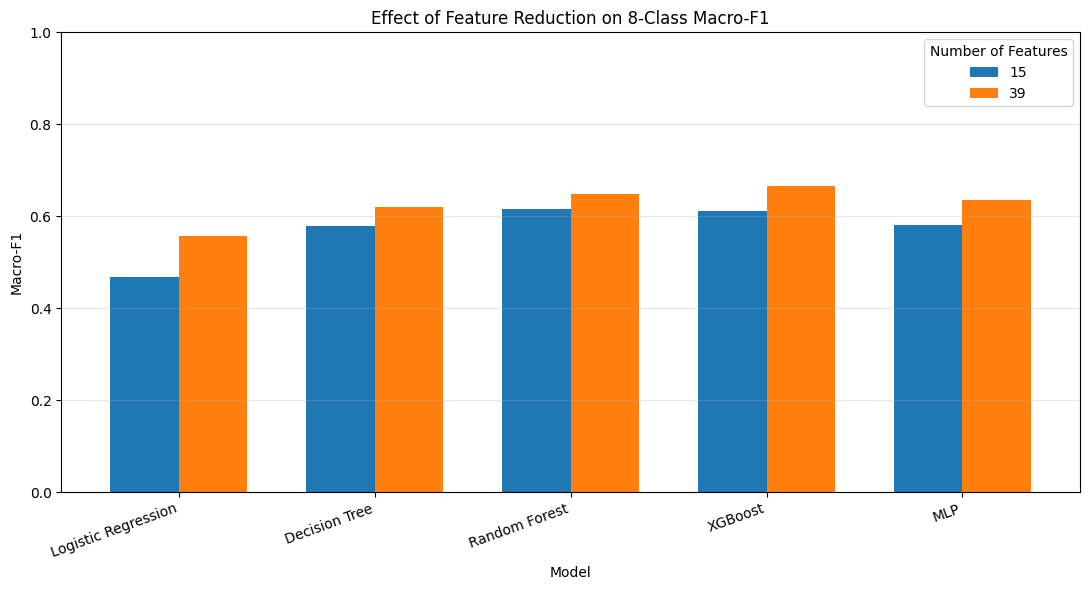

In [ ]:
# Replace missing balancing labels with "None"
eight_class_master_results["Balancing"] = (
    eight_class_master_results["Balancing"]
    .fillna("None")
    .astype(str)
    .str.strip()
)

# Select original, unbalanced experiments
feature_reduction_data = eight_class_master_results[
    (eight_class_master_results["Balancing"] == "None") &
    (eight_class_master_results["Model"] != "Majority Baseline")
].copy()

# Create comparison table
feature_pivot = feature_reduction_data.pivot(
    index="Model",
    columns="Features",
    values="Macro-F1"
)

model_order = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "XGBoost",
    "MLP"
]

feature_pivot = feature_pivot.reindex(model_order)

# Plot
ax = feature_pivot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.7
)

ax.set_title("Effect of Feature Reduction on 8-Class Macro-F1")
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
ax.set_xticklabels(model_order, rotation=20, ha="right")
ax.legend(title="Number of Features")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_PATH, "feature_reduction_8class.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

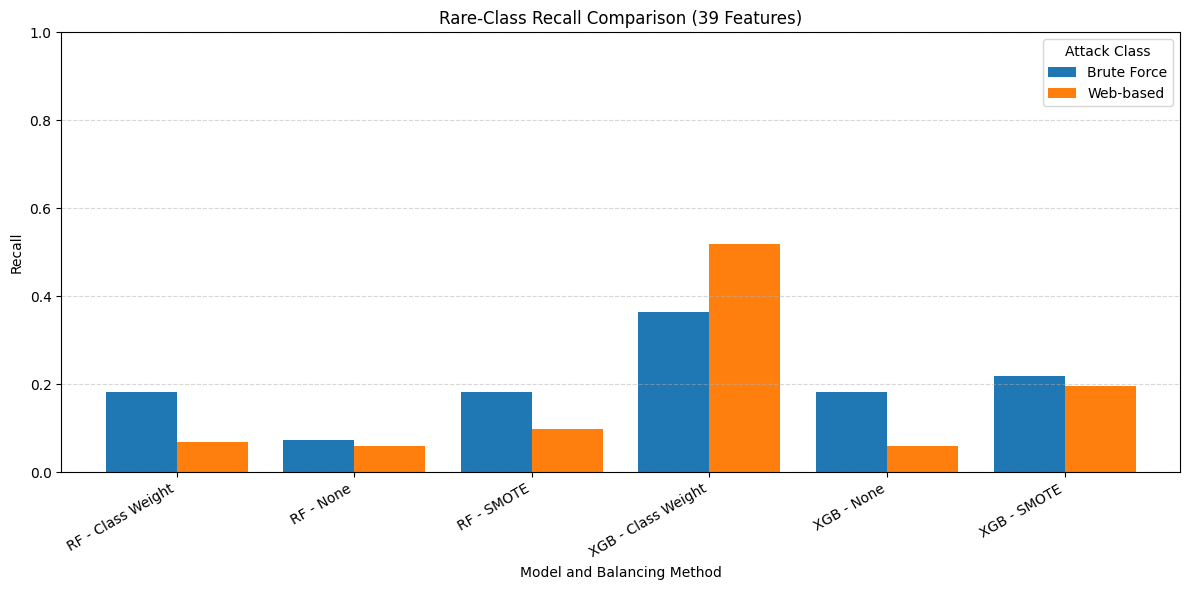

Rare-class recall graph saved successfully.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

results_path = "/content/drive/MyDrive/shared iot/results"
figures_path = os.path.join(results_path, "figures")

# Read reports and standardise their columns
def load_report(filename):
    report = pd.read_csv(os.path.join(results_path, filename))

    # Recover class names if they were saved as the DataFrame index
    if "Class" not in report.columns:
        first_col = report.columns[0]
        report = report.rename(columns={first_col: "Class"})

    # Standardise column names
    report.columns = report.columns.str.strip().str.lower()
    report = report.rename(columns={"class": "Class"})

    # Verify required columns
    if "Class" not in report.columns or "recall" not in report.columns:
        raise ValueError(
            f"Unexpected columns in {filename}: {report.columns.tolist()}"
        )

    report["Class"] = report["Class"].astype(str).str.strip()
    return report


# Load all six reports
reports = {
    "RF - None": load_report("rf_8class_per_class_report.csv"),
    "RF - Class Weight": load_report("rf_weighted_8class_per_class_report.csv"),
    "RF - SMOTE": load_report("rf_smote_8class_39_per_class_report.csv"),
    "XGB - None": load_report("xgb_8class_per_class_report.csv"),
    "XGB - Class Weight": load_report("xgb_weighted_8class_per_class_report.csv"),
    "XGB - SMOTE": load_report("xgb_smote_8class_39_per_class_report.csv")
}

# Extract rare-class recall
rare_classes = ["Brute Force", "Web-based"]
recall_data = []

for model_name, report in reports.items():
    for class_name in rare_classes:
        row = report[report["Class"] == class_name]

        if row.empty:
            raise ValueError(
                f"'{class_name}' not found in the report: {model_name}"
            )

        recall_data.append({
            "Model": model_name,
            "Class": class_name,
            "Recall": float(row["recall"].iloc[0])
        })

recall_df = pd.DataFrame(recall_data)

# Create graph
recall_pivot = recall_df.pivot(
    index="Model",
    columns="Class",
    values="Recall"
)

ax = recall_pivot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Rare-Class Recall Comparison (39 Features)")
ax.set_xlabel("Model and Balancing Method")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=30)
plt.setp(ax.get_xticklabels(), ha="right")
ax.legend(title="Attack Class")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Save graph
plt.savefig(
    os.path.join(figures_path, "rare_class_recall_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Rare-class recall graph saved successfully.")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Predictions from the six trained models
predictions = {
    "RF - None": pred_rf_39_8,
    "RF - Class Weight": pred_rf_weighted_39_8,
    "RF - SMOTE": pred_rf_smote_39_8,
    "XGB - None": pred_xgb_39_8,
    "XGB - Class Weight": pred_xgb_weighted_39_8,
    "XGB - SMOTE": pred_xgb_smote_39_8
}

class_names = label_encoder_8.classes_
fig, axes = plt.subplots(2, 3, figsize=(22, 14))

for ax, (model_name, predictions_model) in zip(axes.flat, predictions.items()):

    cm = confusion_matrix(
        y_test_8_encoded,
        predictions_model,
        labels=np.arange(len(class_names)),
        normalize="true"
    )

    im = ax.imshow(cm, interpolation="nearest", cmap="Blues", vmin=0, vmax=1)

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    ax.set_xticks(np.arange(len(class_names)))
    ax.set_yticks(np.arange(len(class_names)))
    ax.set_xticklabels(class_names, rotation=90, fontsize=8)
    ax.set_yticklabels(class_names, fontsize=8)

    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(
                j, i, f"{cm[i, j]:.2f}",
                ha="center", va="center",
                fontsize=7,
                color="white" if cm[i, j] > 0.5 else "black"
            )

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.75, label="Recall proportion")
fig.suptitle("Eight-Class Confusion Matrices (39 Features)", fontsize=16)
plt.subplots_adjust(wspace=0.35, hspace=0.45, top=0.90)

plt.savefig(
    "/content/drive/MyDrive/shared iot/results/figures/eight_class_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'pred_rf_39_8' is not defined

In [ ]:
import joblib

saved_models = joblib.load(
    "/content/drive/MyDrive/shared iot/8class_saved/trained_models.joblib"
)

print(type(saved_models))

if isinstance(saved_models, dict):
    print("\nSaved model keys:")
    for key, value in saved_models.items():
        print(key, type(value))

<class 'dict'>

Saved model keys:
random_forest <class 'sklearn.ensemble._forest.RandomForestClassifier'>
xgboost <class 'xgboost.sklearn.XGBClassifier'>


In [ ]:
import joblib
import numpy as np

# Load prepared 8-class data
saved_data = joblib.load(
    "/content/drive/MyDrive/shared iot/8class_saved/eight_class_data.joblib"
)

X_train_39_8 = saved_data["X_train_39"]
X_test_39_8 = saved_data["X_test_39"]

X_train_15_8 = saved_data["X_train_15"]
X_test_15_8 = saved_data["X_test_15"]

y_train_8 = saved_data["y_train"]
y_test_8 = saved_data["y_test"]

y_train_8_encoded = saved_data["y_train_encoded"]
y_test_8_encoded = saved_data["y_test_encoded"]

top_15_features_8 = saved_data["top_15_features"]
label_encoder_8 = saved_data["label_encoder"]

# Load original trained models
saved_models = joblib.load(
    "/content/drive/MyDrive/shared iot/8class_saved/trained_models.joblib"
)

rf_8_original = saved_models["random_forest"]
xgb_8_original = saved_models["xgboost"]

print("Data and original models restored successfully.")
print("Training data:", X_train_39_8.shape)
print("Testing data:", X_test_39_8.shape)
print("15-feature training data:", X_train_15_8.shape)
print("Classes:", list(label_encoder_8.classes_))

Data and original models restored successfully.
Training data: (539807, 39)
Testing data: (134949, 39)
15-feature training data: (539807, 15)
Classes: ['Benign', 'Brute Force', 'DDoS', 'DoS', 'Mirai', 'Recon', 'Spoofing', 'Web-based']


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

saved_data = joblib.load(
    "/content/drive/MyDrive/shared iot/8class_saved/eight_class_data.joblib"
)

saved_models = joblib.load(
    "/content/drive/MyDrive/shared iot/8class_saved/trained_models.joblib"
)

X_test_39_8 = saved_data["X_test_39"]
y_test_8_encoded = saved_data["y_test_encoded"]
label_encoder_8 = saved_data["label_encoder"]

rf_8_original = saved_models["random_forest"]
xgb_8_original = saved_models["xgboost"]

print("Data and models loaded.")

Data and models loaded.


In [3]:
pred_rf_39_8 = rf_8_original.predict(X_test_39_8)
pred_xgb_39_8 = xgb_8_original.predict(X_test_39_8)

print("Original model predictions generated.")

Original model predictions generated.


/tmp/ipykernel_42758/980122153.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


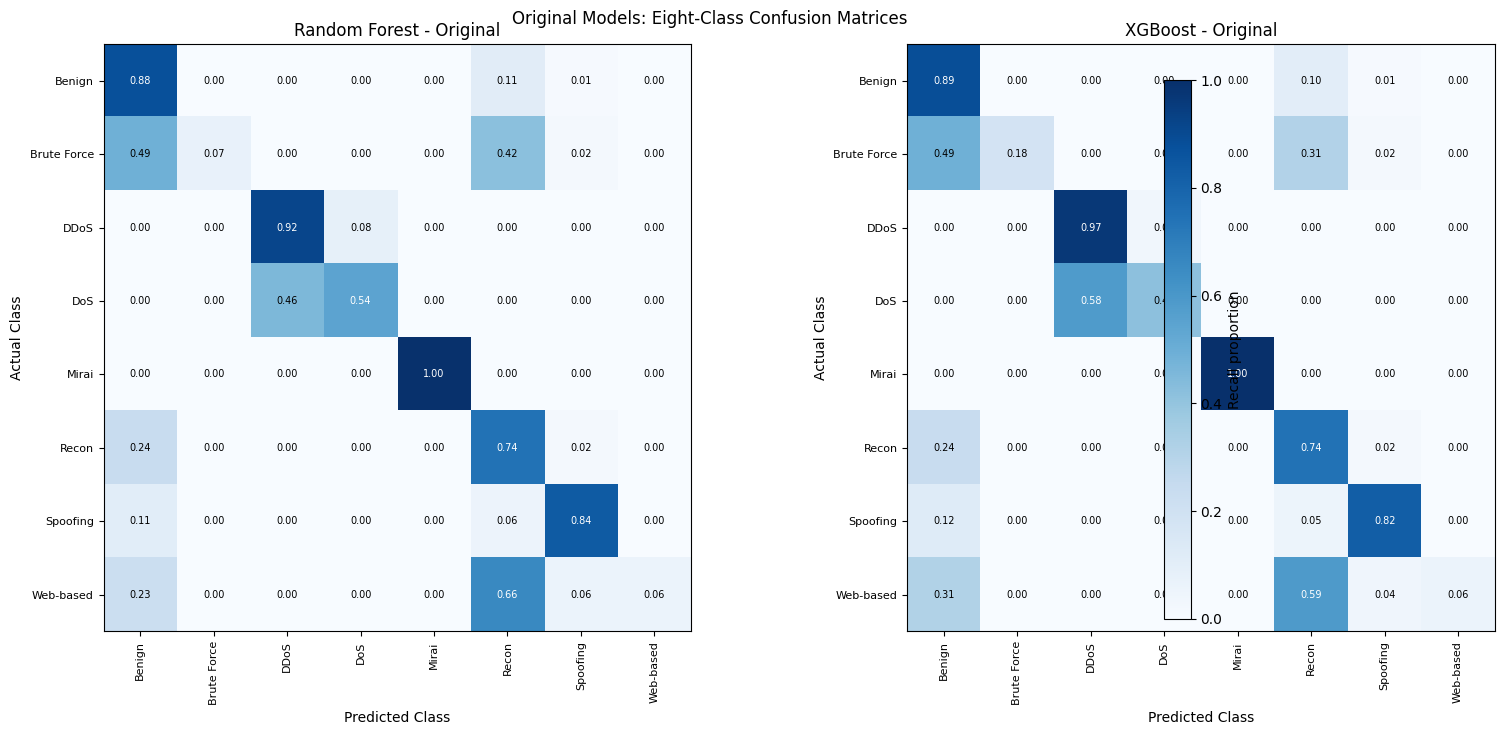

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

class_names = label_encoder_8.classes_

# Convert RF class-name predictions into integer labels
pred_rf_numeric = label_encoder_8.transform(pred_rf_39_8)

# XGBoost predictions are already integers
pred_xgb_numeric = pred_xgb_39_8

original_predictions = {
    "Random Forest - Original": pred_rf_numeric,
    "XGBoost - Original": pred_xgb_numeric
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (model_name, predictions) in zip(axes, original_predictions.items()):

    cm = confusion_matrix(
        y_test_8_encoded,
        predictions,
        labels=np.arange(8),
        normalize="true"
    )

    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    ax.set_xticklabels(class_names, rotation=90, fontsize=8)
    ax.set_yticklabels(class_names, fontsize=8)

    for i in range(8):
        for j in range(8):
            ax.text(
                j, i, f"{cm[i, j]:.2f}",
                ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > 0.5 else "black"
            )

fig.colorbar(im, ax=axes, label="Recall proportion")
fig.suptitle("Original Models: Eight-Class Confusion Matrices")
plt.tight_layout()

figures_path = "/content/drive/MyDrive/shared iot/results/figures"
os.makedirs(figures_path, exist_ok=True)

plt.savefig(
    os.path.join(figures_path, "eight_class_original_confusion_matrices.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
print("y_test_8_encoded:")
print("Type:", type(y_test_8_encoded))
print("Dtype:", np.asarray(y_test_8_encoded).dtype)
print("Sample:", np.unique(y_test_8_encoded)[:10])

print("\nRF predictions:")
print("Dtype:", np.asarray(pred_rf_39_8).dtype)
print("Sample:", np.unique(pred_rf_39_8)[:10])

print("\nXGB predictions:")
print("Dtype:", np.asarray(pred_xgb_39_8).dtype)
print("Sample:", np.unique(pred_xgb_39_8)[:10])

print("\nEncoder classes:")
print(label_encoder_8.classes_)

y_test_8_encoded:
Type: <class 'numpy.ndarray'>
Dtype: int64
Sample: [0 1 2 3 4 5 6 7]

RF predictions:
Dtype: object
Sample: ['Benign' 'Brute Force' 'DDoS' 'DoS' 'Mirai' 'Recon' 'Spoofing'
 'Web-based']

XGB predictions:
Dtype: int64
Sample: [0 1 2 3 4 5 6 7]

Encoder classes:
['Benign' 'Brute Force' 'DDoS' 'DoS' 'Mirai' 'Recon' 'Spoofing'
 'Web-based']


In [11]:
import os

saved_folder = "/content/drive/MyDrive/shared iot/8class_saved"

for root, dirs, files in os.walk(saved_folder):
    for file in files:
        print(os.path.join(root, file))

/content/drive/MyDrive/shared iot/8class_saved/eight_class_data.joblib
/content/drive/MyDrive/shared iot/8class_saved/trained_models.joblib


In [12]:
import os

figures_path = "/content/drive/MyDrive/shared iot/results/figures"

print("Current figures in Drive:\n")

for filename in sorted(os.listdir(figures_path)):
    if filename.endswith(".png"):
        print(filename)

Current figures in Drive:

accuracy_comparison.png
accuracy_comparison_8class_15.png
accuracy_comparison_8class_39.png
accuracy_comparison_final.png
benign_recall_balancing_final.png
confusion_matrices.png
feature_count_vs_macro_f1.png
feature_reduction_8class.png
feature_reduction_final.png
macro_f1_comparison.png
macro_f1_comparison_8class_15.png
macro_f1_comparison_8class_39.png
macro_f1_comparison_final.png
random_forest_confusion_matrices.png
rare_class_recall_comparison.png


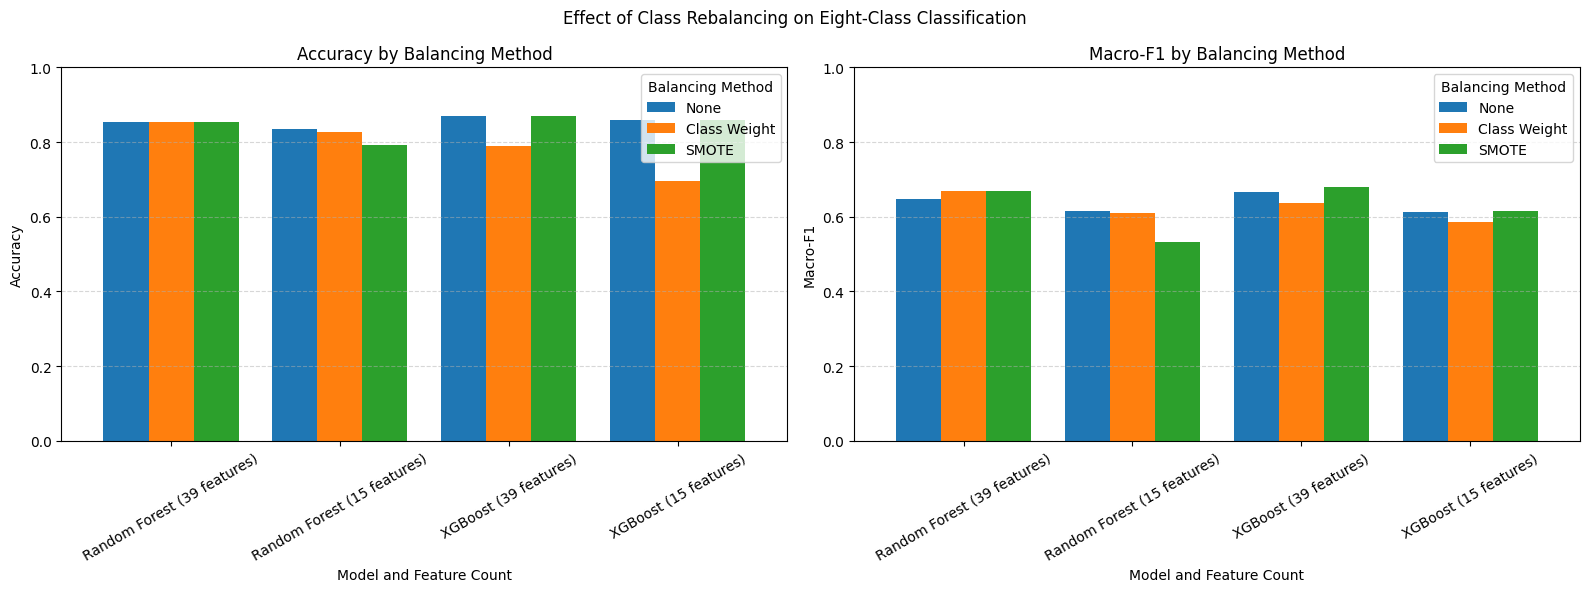

Balancing comparison graph saved successfully.


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import os

results_path = "/content/drive/MyDrive/shared iot/results"
figures_path = os.path.join(results_path, "figures")

# Load the five experiment result files
files = [
    "eight_class_results.csv",
    "rf_weighted_8class_results.csv",
    "xgb_weighted_8class_results.csv",
    "rf_smote_8class_results.csv",
    "xgb_smote_8class_results.csv"
]

all_results = []

for filename in files:
    temp = pd.read_csv(os.path.join(results_path, filename))
    all_results.append(temp)

# Combine results
balancing_df = pd.concat(all_results, ignore_index=True)

# Clean column values
balancing_df.columns = balancing_df.columns.str.strip()
balancing_df["Balancing"] = (
    balancing_df["Balancing"].fillna("None").astype(str).str.strip()
)
balancing_df["Features"] = pd.to_numeric(balancing_df["Features"])

# Keep only RF and XGBoost
balancing_df = balancing_df[
    balancing_df["Model"].isin(["Random Forest", "XGBoost"])
].copy()

# Keep only the three balancing conditions
balancing_df = balancing_df[
    balancing_df["Balancing"].isin(["None", "Class Weight", "SMOTE"])
].copy()

# Create readable labels
balancing_df["Model_Features"] = (
    balancing_df["Model"] + " (" +
    balancing_df["Features"].astype(str) + " features)"
)

model_order = [
    "Random Forest (39 features)",
    "Random Forest (15 features)",
    "XGBoost (39 features)",
    "XGBoost (15 features)"
]

balancing_order = ["None", "Class Weight", "SMOTE"]

# Plot Accuracy and Macro-F1
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, metric, title in zip(
    axes,
    ["Accuracy", "Macro-F1"],
    ["Accuracy by Balancing Method", "Macro-F1 by Balancing Method"]
):
    pivot = balancing_df.pivot(
        index="Model_Features",
        columns="Balancing",
        values=metric
    )

    pivot = pivot.reindex(index=model_order, columns=balancing_order)

    pivot.plot(kind="bar", ax=ax, width=0.8)

    ax.set_title(title)
    ax.set_xlabel("Model and Feature Count")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.legend(title="Balancing Method")

plt.suptitle("Effect of Class Rebalancing on Eight-Class Classification")
plt.tight_layout()

plt.savefig(
    os.path.join(figures_path, "balancing_method_comparison_8class.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Balancing comparison graph saved successfully.")